# Noise filtering and painting segmentation for descriptor matching

Preprocessing of the **qsd1_w4** query images before local-feature (SIFT) extraction:

1. **Noise detection:** flag images with impulse noise and apply a 3×3 median filter only to those.
2. **Segmentation:** split each image into its individual paintings.
3. **Feature extraction:** compute keypoints and descriptors for each painting separately.

## Setup

In [1]:
from __future__ import annotations

import pickle
import sys
import time
from dataclasses import dataclass
from pathlib import Path

import cv2
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.ndimage import binary_fill_holes
from sklearn.metrics import balanced_accuracy_score, precision_score, recall_score

# Presentation style
plt.rcParams.update({
    "figure.dpi": 110, "savefig.bbox": "tight",
    "font.size": 13, "axes.titlesize": 15, "axes.titleweight": "bold", "axes.labelsize": 13,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
NOISY, CLEAN, ACCENT = "#D1495B", "#2E86AB", "#2A9D8F"
COLOUR_MASK, EDGE_MASK, NEUTRAL = "#E9A23B", "#6A4C93", "#8D99AE"
PAINTING_COLORS = plt.cm.tab10.colors


def find_project_root():
    for directory in (Path.cwd(), *Path.cwd().parents):
        if (directory / "data").is_dir() and (directory / "src").is_dir():
            return directory
    raise FileNotFoundError("Could not find the project root")


ROOT = find_project_root()
DATA_DIR = ROOT / "data"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.segmentation import foreground_mask

In [2]:
def read_bgr(path):
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read image: {path}")
    return image


def to_gray(image):
    return image if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


def rgb(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def to_bgr(color):
    r, g, b = (int(255 * c) for c in mcolors.to_rgb(color))
    return b, g, r


def show(ax, image, title=None, **kwargs):
    ax.imshow(rgb(image), **kwargs)
    ax.axis("off")
    if title:
        ax.set_title(title)


def zoom_window(shape, frac=0.25, center=None):
    """Square crop (as row/column slices) of `frac` x the short side, centred on `center`."""
    h, w = shape[:2]
    size = max(16, int(frac * min(h, w)))
    cy, cx = center if center is not None else (h // 2, w // 2)
    y0 = int(np.clip(cy - size // 2, 0, max(0, h - size)))
    x0 = int(np.clip(cx - size // 2, 0, max(0, w - size)))
    return slice(y0, y0 + size), slice(x0, x0 + size)

## 1. Data

Query images (some with impulse noise) and their non-augmented twins. An image is labelled *noisy* when it differs from its twin.

In [3]:
@dataclass(frozen=True)
class ImageDataset:
    """Image paths paired with integer IDs in deterministic filename order."""

    paths: tuple[Path, ...]
    ids: np.ndarray

    def __len__(self) -> int:
        return len(self.paths)


def image_id(path: Path) -> int:
    """Parse IDs from both `00012.jpg` and `bbdd_00012.jpg`."""
    return int(path.stem.rsplit("_", 1)[-1])


def load_image_dataset(directory: str | Path) -> ImageDataset:
    directory = Path(directory)
    paths = tuple(sorted(directory.glob("*.jpg")))  # sorted: row i must match query image i
    if not paths:
        raise FileNotFoundError(f"No JPG images found in {directory}")
    ids = np.asarray([image_id(path) for path in paths], dtype=int)
    if len(np.unique(ids)) != len(ids):
        raise ValueError(f"Duplicate image IDs found in {directory}")
    return ImageDataset(paths=paths, ids=ids)


def load_ground_truth(path: str | Path) -> list[list[int]]:
    with Path(path).open("rb") as stream:
        values = pickle.load(stream)
    return [[int(image_id) for image_id in relevant] for relevant in values]


def noise_ground_truth(dataset: ImageDataset, reference: ImageDataset) -> np.ndarray:
    """True where an image differs from its non-augmented twin."""
    reference_paths = dict(zip(reference.ids.tolist(), reference.paths))
    missing = sorted(set(dataset.ids.tolist()) - set(reference_paths))
    if missing:
        raise ValueError(f"Missing non-augmented images for IDs: {missing}")

    labels = []
    for path, image_id_value in zip(dataset.paths, dataset.ids):
        image, twin = read_bgr(path), read_bgr(reference_paths[int(image_id_value)])
        if image.shape != twin.shape:
            raise ValueError(f"Shape mismatch for ID {image_id_value}: {image.shape} vs {twin.shape}")
        labels.append(not np.array_equal(image, twin))
    return np.asarray(labels, dtype=bool)

In [4]:
train_dataset = load_image_dataset(DATA_DIR / "qsd1_w4")
non_augmented = load_image_dataset(DATA_DIR / "qsd1_w4" / "non_augmented")
ground_truth = load_ground_truth(DATA_DIR / "qsd1_w4" / "gt_corresps.pkl")
noise_labels = noise_ground_truth(train_dataset, non_augmented)

print(f"{len(train_dataset)} images: {noise_labels.sum()} noisy, {(~noise_labels).sum()} clean")

30 images: 21 noisy, 9 clean


## 2. Dataset overview

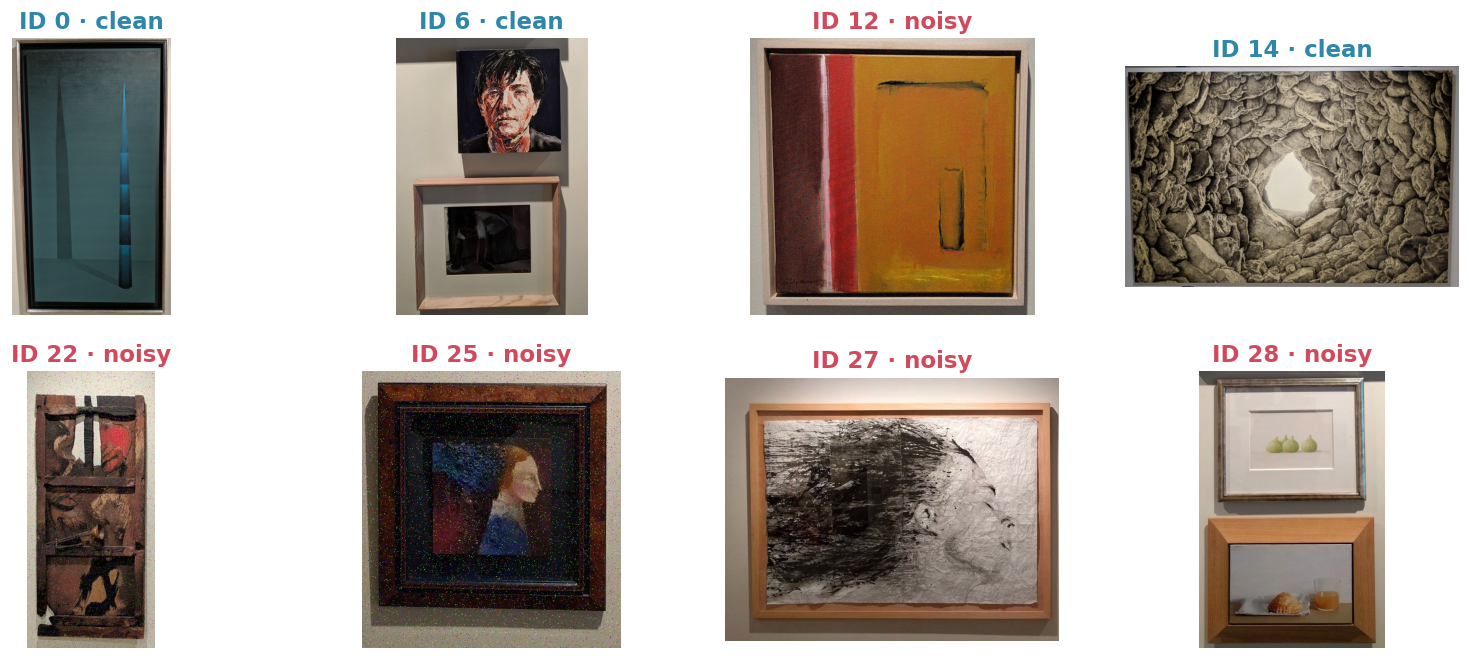

In [5]:
def plot_samples(dataset, labels, n=8, ncols=4, seed=52):
    indices = np.sort(np.random.default_rng(seed).choice(len(dataset), size=n, replace=False))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, i in zip(axes, indices):
        show(ax, read_bgr(dataset.paths[i]))
        ax.set_title(f"ID {dataset.ids[i]} · {'noisy' if labels[i] else 'clean'}",
                     color=NOISY if labels[i] else CLEAN)
    for ax in axes[n:]:
        ax.axis("off")
    plt.show()


plot_samples(train_dataset, noise_labels)

## 3. Noise detector

A pixel is **isolated** if it differs by more than `tp` grey levels from all 8 neighbours. An image is flagged as noisy when more than `tf` % of its pixels are isolated.
An additive-noise detector (estimated σ, Immerkaer) is also searched and combined with OR. Thresholds are chosen by grid search on balanced accuracy against the noise labels.

In [6]:
def isolated_map(gray):
    """Minimum absolute difference between each pixel and its 8 neighbours (uint8)."""
    padded = cv2.copyMakeBorder(gray, 1, 1, 1, 1, cv2.BORDER_REFLECT)
    h, w = gray.shape
    result = None
    for dy in (-1, 0, 1):
        for dx in (-1, 0, 1):
            if dy or dx:
                diff = cv2.absdiff(gray, padded[1 + dy:1 + dy + h, 1 + dx:1 + dx + w])
                result = diff if result is None else np.minimum(result, diff)
    return result


def estimate_sigma(gray):
    """Immerkaer (1996) fast noise-sigma estimate."""
    kernel = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float64)
    conv = cv2.filter2D(gray.astype(np.float64), -1, kernel, borderType=cv2.BORDER_REFLECT)
    h, w = gray.shape
    return np.sqrt(np.pi / 2) / (6 * (w - 2) * (h - 2)) * np.abs(conv[1:-1, 1:-1]).sum()

In [7]:
tps = [5, 10, 20, 30, 40, 60, 80, 100, 150]
tfs = [0.05, 0.1, 0.25, 0.5, 1, 2, 5, 10]                    # % of pixels
sigma_thresholds = [np.inf, 20, 16, 12, 10, 8, 6, 4, 2]      # inf = additive detector disabled

# Per image: histogram of the isolated map (lets us score every tp at once) and sigma
grays = [to_gray(read_bgr(path)) for path in train_dataset.paths]
iso_hist = np.stack([np.bincount(isolated_map(g).ravel(), minlength=256) for g in grays])
sigmas = np.array([estimate_sigma(g) for g in grays])

# % of pixels above each tp = 100 * (1 - cumulative share up to tp)
iso_pct = 100 * (1 - np.cumsum(iso_hist, axis=1)[:, tps] / iso_hist.sum(axis=1, keepdims=True))

grid = np.array([[balanced_accuracy_score(noise_labels, iso_pct[:, j] > tf) for j in range(len(tps))]
                 for tf in tfs])
tf_i, tp_i = np.unravel_index(grid.argmax(), grid.shape)
best_tp, best_tf = tps[tp_i], tfs[tf_i]
impulse_flag = iso_pct[:, tp_i] > best_tf

# Additive detector: ties favour "disabled" because inf comes first
sigma_scores = [balanced_accuracy_score(noise_labels, impulse_flag | (sigmas > s)) for s in sigma_thresholds]
best_sigma = sigma_thresholds[int(np.argmax(sigma_scores))]
predicted_noise = impulse_flag | (sigmas > best_sigma)

DENOISE = dict(tp=best_tp, tf=best_tf, sigma_thr=best_sigma)
print(f"Thresholds: {DENOISE}")
print(f"Balanced accuracy {balanced_accuracy_score(noise_labels, predicted_noise):.3f} | "
      f"precision {precision_score(noise_labels, predicted_noise):.3f} | "
      f"recall {recall_score(noise_labels, predicted_noise):.3f}")
print(f"{(predicted_noise & noise_labels).sum()}/{noise_labels.sum()} noisy images detected, "
      f"{(predicted_noise & ~noise_labels).sum()}/{(~noise_labels).sum()} false alarms")

Thresholds: {'tp': 30, 'tf': 0.1, 'sigma_thr': inf}
Balanced accuracy 0.762 | precision 1.000 | recall 0.524
11/21 noisy images detected, 0/9 false alarms


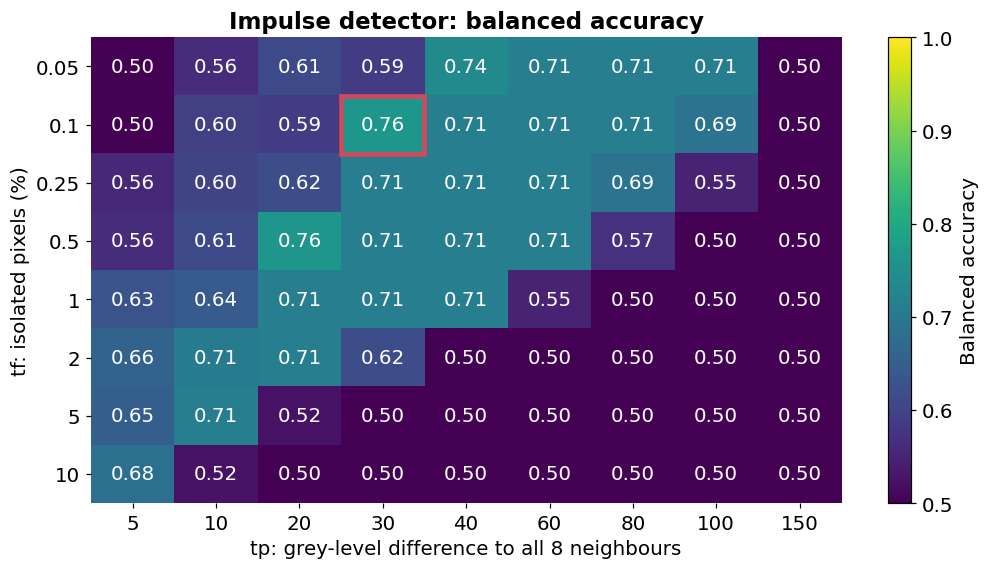

In [8]:
fig, ax = plt.subplots(figsize=(11, 5.5))
heatmap = ax.imshow(grid, cmap="viridis", vmin=0.5, vmax=1, aspect="auto")
ax.set_xticks(range(len(tps)), [str(t) for t in tps])
ax.set_yticks(range(len(tfs)), [str(t) for t in tfs])
ax.set(xlabel="tp: grey-level difference to all 8 neighbours", ylabel="tf: isolated pixels (%)",
       title="Impulse detector: balanced accuracy")
for i in range(len(tfs)):
    for j in range(len(tps)):
        dark = (grid[i, j] - 0.5) / 0.5 < 0.6
        ax.text(j, i, f"{grid[i, j]:.2f}", ha="center", va="center", color="white" if dark else "black")
ax.add_patch(plt.Rectangle((tp_i - 0.5, tf_i - 0.5), 1, 1, fill=False, ec=NOISY, lw=3))
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(heatmap, ax=ax, label="Balanced accuracy")
plt.show()

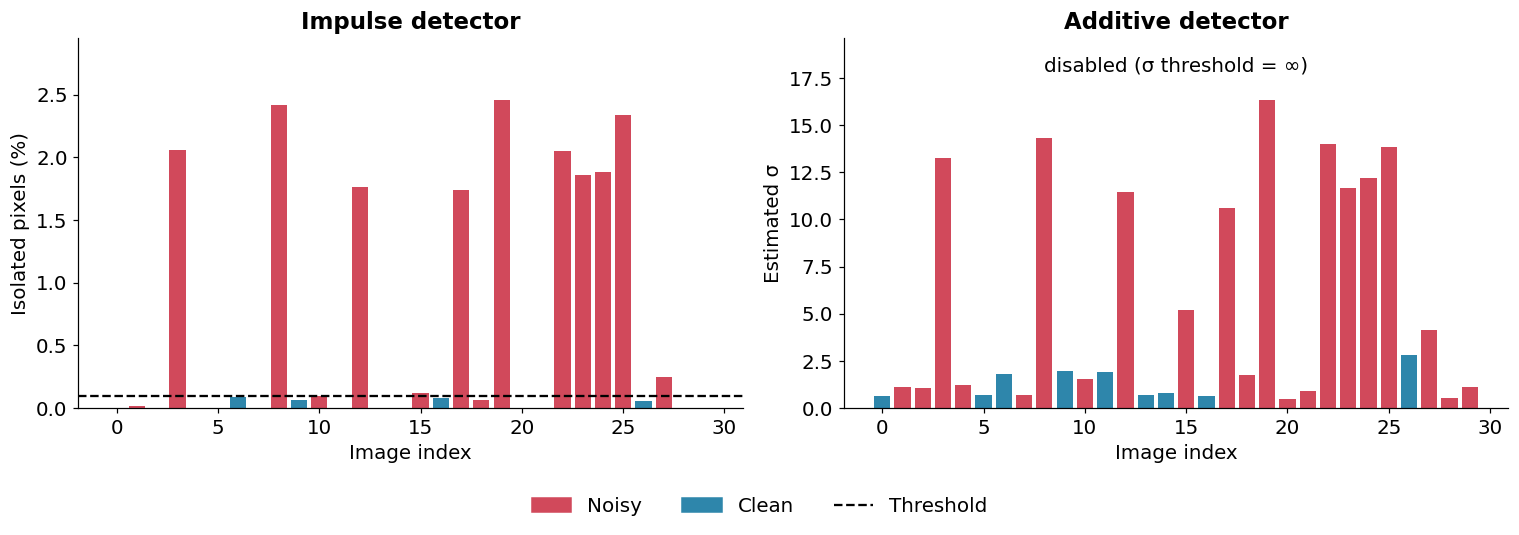

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
panels = [(iso_pct[:, tp_i], best_tf, "Impulse detector", "Isolated pixels (%)"),
          (sigmas, best_sigma, "Additive detector", "Estimated σ")]
for ax, (values, threshold, title, ylabel) in zip(axes, panels):
    ax.bar(np.arange(len(values)), values, color=np.where(noise_labels, NOISY, CLEAN))
    ax.set(title=title, xlabel="Image index", ylabel=ylabel, ylim=(0, max(values) * 1.2))
    if np.isfinite(threshold):
        ax.axhline(threshold, color="k", ls="--", lw=1.5)
    else:
        ax.text(0.5, 0.95, "disabled (σ threshold = ∞)", transform=ax.transAxes, ha="center", va="top")
fig.legend(handles=[Patch(color=NOISY, label="Noisy"), Patch(color=CLEAN, label="Clean"),
                    Line2D([], [], color="k", ls="--", label="Threshold")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
plt.show()

**Results.** Best thresholds: `tp = 30`, `tf = 0.1 %`; the additive detector adds nothing (σ threshold = ∞).
On the 30 images there are no false alarms (precision 1.0) and 11 of 21 noisy images are detected (recall 0.52).
The 10 missed images differ from their clean twin but show no excess of isolated pixels.

## 4. Conditional denoising

A 3×3 median filter is applied only to flagged images, so clean images keep their detail.

In [10]:
def denoise_if_noisy(image, tp, tf, sigma_thr=np.inf, ksize=3, return_info=False):
    """Median-filter the image only if the impulse or additive detector fires."""
    gray = to_gray(image)
    isolated_pct = 100 * np.mean(isolated_map(gray) > tp)
    sigma = estimate_sigma(gray) if np.isfinite(sigma_thr) else 0.0
    noisy = bool(isolated_pct > tf or sigma > sigma_thr)

    output = cv2.medianBlur(image, ksize) if noisy else image
    if return_info:
        return output, {"noisy": noisy, "isolated_pct": float(isolated_pct), "sigma": float(sigma)}
    return output

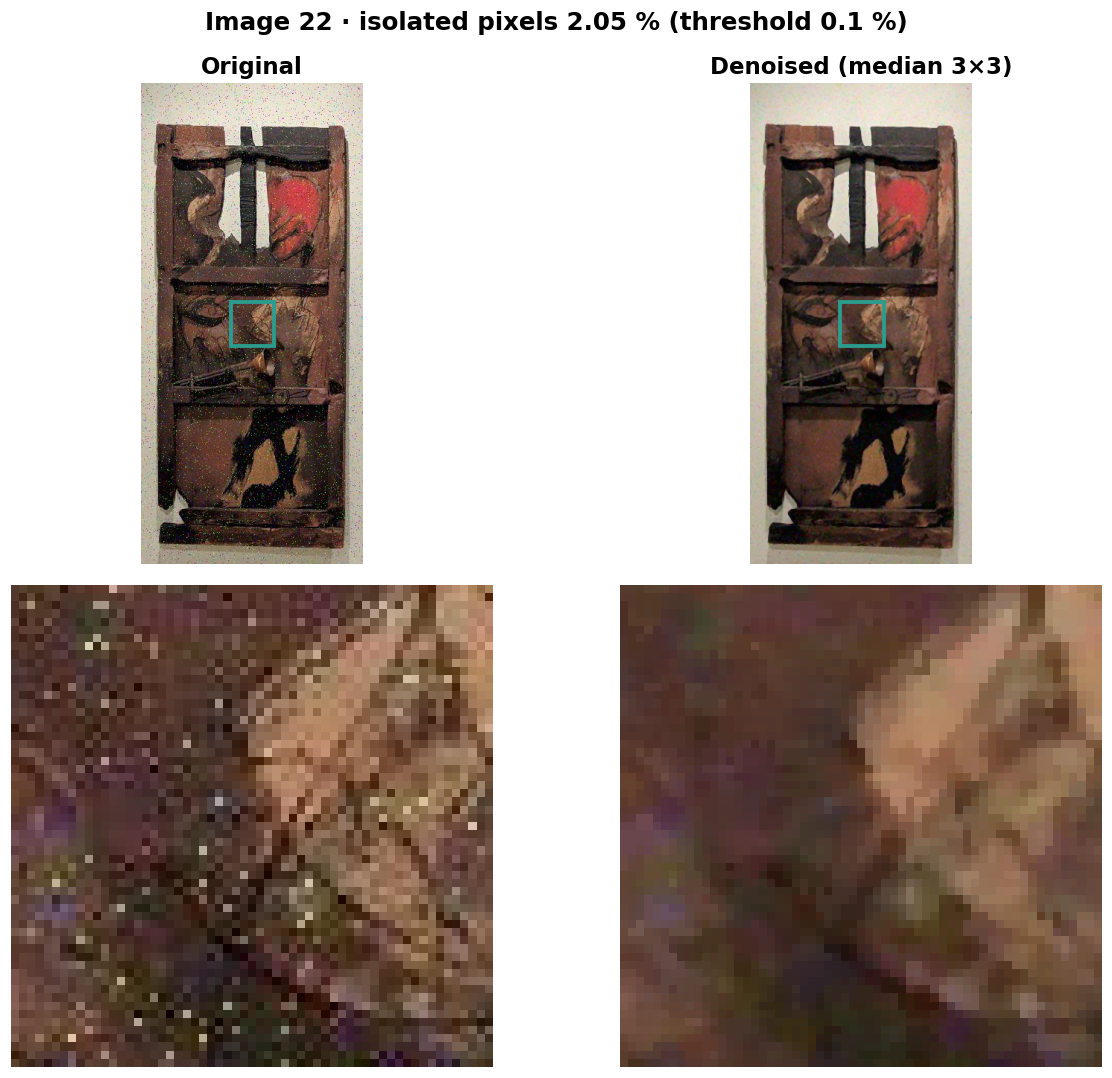

In [11]:
def plot_denoising(image, denoise_params, title="", zoom_frac=0.2):
    denoised, info = denoise_if_noisy(image, **denoise_params, return_info=True)
    ys, xs = zoom_window(image.shape, zoom_frac)
    size = ys.stop - ys.start

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    for col, (img, name) in enumerate([(image, "Original"), (denoised, "Denoised (median 3×3)")]):
        show(axes[0, col], img, name)
        axes[0, col].add_patch(plt.Rectangle((xs.start, ys.start), size, size, fill=False, ec=ACCENT, lw=2.5))
        show(axes[1, col], img[ys, xs], interpolation="nearest")
    fig.suptitle(f"{title} · isolated pixels {info['isolated_pct']:.2f} % "
                 f"(threshold {denoise_params['tf']} %)", fontsize=16, fontweight="bold")
    fig.tight_layout()
    plt.show()


EXAMPLE_NOISY = 22
plot_denoising(read_bgr(train_dataset.paths[EXAMPLE_NOISY]), DENOISE,
               title=f"Image {train_dataset.ids[EXAMPLE_NOISY]}")

## 5. Painting segmentation

Foreground = colour segmenter (`src.segmentation`) **or** edge cue, which catches low-contrast paintings such as a pale frame on a pale wall.
Nearby components are merged and each group gets a rotated bounding box. At most two paintings per image, ordered left to right.

In [12]:
def edge_foreground(image, work_size=400, close_frac=0.025):
    """Painting mask from edges: close the contours, fill them and drop thin lines."""
    h, w = image.shape[:2]
    scale = min(1.0, work_size / max(h, w))
    small = cv2.resize(image, (max(1, round(w * scale)), max(1, round(h * scale))),
                       interpolation=cv2.INTER_AREA) if scale < 1 else image

    gray = cv2.GaussianBlur(to_gray(small), (5, 5), 0)
    median = float(np.median(gray))
    edges = cv2.Canny(gray, int(max(0, 0.66 * median)), int(min(255, 1.33 * median)))

    k = max(3, int(round(close_frac * min(gray.shape))) | 1)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    closed = cv2.morphologyEx(cv2.dilate(edges, np.ones((3, 3), np.uint8)), cv2.MORPH_CLOSE, kernel)
    filled = cv2.morphologyEx(binary_fill_holes(closed > 0).astype(np.uint8), cv2.MORPH_OPEN, kernel)
    return cv2.resize(filled.astype(np.float32), (w, h), interpolation=cv2.INTER_LINEAR) > 0.5


def _boxes_near(a, b, gap):
    (xa, ya, wa, ha), (xb, yb, wb, hb) = a, b
    return not (xa + wa + gap < xb or xb + wb + gap < xa or ya + ha + gap < yb or yb + hb + gap < ya)


def find_paintings(image, max_paintings=2, component_min_area=0.005, painting_min_area=0.02,
                   merge_gap_fraction=0.04, use_edges=True):
    """Split an image into paintings (left to right).

    Returns (parts, debug). Each part has bbox, polygon, crop and mask (inside the crop);
    debug holds the colour / edge / combined masks for plotting.
    """
    h, w = image.shape[:2]

    # 1. Colour and edge cues (each ignored when it degenerates to "everything")
    colour = foreground_mask(image, min_area=component_min_area, keep="all")
    colour_used = colour.mean() <= 0.98
    colour = colour if colour_used else np.zeros_like(colour)

    edge = edge_foreground(image) if use_edges else np.zeros_like(colour)
    edge_used = use_edges and edge.mean() <= 0.9
    edge = edge if edge_used else np.zeros_like(colour)

    # 2. Connected components, merging those whose boxes are close (union-find)
    count, labels, stats, _ = cv2.connectedComponentsWithStats((colour | edge).astype(np.uint8), connectivity=8)
    ids = [i for i in range(1, count) if stats[i, cv2.CC_STAT_AREA] >= component_min_area * h * w]
    parent = {i: i for i in ids}

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    gap = merge_gap_fraction * min(h, w)
    for n, a in enumerate(ids):
        for b in ids[n + 1:]:
            if _boxes_near(stats[a, :4], stats[b, :4], gap):
                parent[find(b)] = find(a)

    groups = {}
    for i in ids:
        groups.setdefault(find(i), []).append(i)

    # 3. Rotated box per group; keep the largest ones, ordered left to right
    regions = []
    for members in groups.values():
        rows, cols = np.nonzero(np.isin(labels, members))
        if len(rows) >= painting_min_area * h * w:
            box = cv2.boxPoints(cv2.minAreaRect(np.column_stack((cols, rows)).astype(np.float32)))
            regions.append((len(rows), box))
    regions = sorted(regions, key=lambda r: r[0], reverse=True)[:max_paintings]
    regions.sort(key=lambda r: r[1][:, 0].mean())

    parts, combined = [], np.zeros((h, w), dtype=bool)
    for _, box in regions:
        filled = np.zeros((h, w), dtype=np.uint8)
        cv2.fillConvexPoly(filled, np.round(box).astype(np.int32), 1)
        ys, xs = np.nonzero(filled)
        if len(xs) == 0:
            continue
        x0, x1, y0, y1 = xs.min(), xs.max() + 1, ys.min(), ys.max() + 1
        combined |= filled.astype(bool)
        parts.append({"bbox": (int(x0), int(y0), int(x1), int(y1)), "polygon": box,
                      "crop": image[y0:y1, x0:x1], "mask": filled[y0:y1, x0:x1] * 255})

    if not parts:  # fallback: whole image
        parts = [{"bbox": (0, 0, w, h), "polygon": None, "crop": image, "mask": None}]
        combined[:] = True

    return parts, {"colour": colour, "edge": edge, "combined": combined,
                   "colour_used": colour_used, "edge_used": edge_used}

## 6. Feature extraction

Denoise, split, then extract keypoints and descriptors from each painting. Keypoints are stored in original-image coordinates.

In [13]:
def create_feature_detector(method="SIFT", nfeatures=3000):
    factories = {"SIFT": lambda: cv2.SIFT_create(nfeatures=nfeatures),
                 "ORB": lambda: cv2.ORB_create(nfeatures=nfeatures),
                 "AKAZE": lambda: cv2.AKAZE_create()}
    if method.upper() not in factories:
        raise ValueError(f"Unsupported method: {method}")
    return factories[method.upper()]()


def keypoints_to_array(keypoints, x_offset=0, y_offset=0):
    """Nx7 array (x, y, size, angle, response, octave, class_id) shifted by the crop offset."""
    return np.array([[kp.pt[0] + x_offset, kp.pt[1] + y_offset, kp.size, kp.angle,
                      kp.response, kp.octave, kp.class_id] for kp in keypoints],
                    dtype=np.float32).reshape(-1, 7)


def describe_part(detector, part):
    """Keypoints (original-image coordinates) and descriptors of one painting."""
    x0, y0 = part["bbox"][:2]
    keypoints, descriptors = detector.detectAndCompute(to_gray(part["crop"]), part["mask"])
    return keypoints_to_array(keypoints, x0, y0), descriptors


def extract_features(dataset, denoise_params, method="SIFT", nfeatures=3000, **seg_kwargs):
    """Returns {image_id: {"path", "noisy", "parts": [{bbox, polygon, keypoints, descriptors}]}}."""
    detector = create_feature_detector(method, nfeatures)
    features, elapsed = {}, 0.0

    for path, image_id_value in zip(dataset.paths, dataset.ids):
        image, info = denoise_if_noisy(read_bgr(path), **denoise_params, return_info=True)
        parts_out = []
        for part in find_paintings(image, **seg_kwargs)[0]:
            start = time.perf_counter()
            keypoints, descriptors = describe_part(detector, part)
            elapsed += time.perf_counter() - start
            parts_out.append({"bbox": part["bbox"], "polygon": part["polygon"],
                              "keypoints": keypoints, "descriptors": descriptors})
        features[int(image_id_value)] = {"path": str(path), "noisy": info["noisy"], "parts": parts_out}

    counts = [len(p["keypoints"]) for item in features.values() for p in item["parts"]]
    split = sum(len(item["parts"]) > 1 for item in features.values())
    print(f"{method}: {len(features)} images -> {len(counts)} paintings ({split} images split) in {elapsed:.2f} s")
    print(f"Keypoints per painting: mean {np.mean(counts):.0f}, median {np.median(counts):.0f}, "
          f"min-max {min(counts)}-{max(counts)}")
    return features

In [14]:
features = extract_features(train_dataset, DENOISE, method="SIFT")

summary = pd.DataFrame({
    "noisy (truth)": noise_labels,
    "noisy (detected)": [features[int(i)]["noisy"] for i in train_dataset.ids],
    "paintings": [len(features[int(i)]["parts"]) for i in train_dataset.ids],
    "keypoints": [[len(p["keypoints"]) for p in features[int(i)]["parts"]] for i in train_dataset.ids],
}, index=pd.Index(train_dataset.ids, name="id"))
summary

SIFT: 30 images -> 37 paintings (7 images split) in 6.17 s
Keypoints per painting: mean 1636, median 1195, min-max 39-3001


,noisy (truth),noisy (detected),paintings,keypoints
id,,,,
0,False,False,1,[2541]
1,True,False,1,[1752]
2,True,False,2,"[659, 232]"
3,True,True,1,[469]
4,True,False,1,[3000]
5,False,False,1,[3000]
6,False,False,1,[907]
7,True,False,1,[2320]
8,True,True,1,[319]


**Results.** 7 of the 30 images are split into two paintings (IDs 2, 9, 10, 14, 16, 18 and 24).

## 7. Pipeline visualization

Example on image 24 (noisy, two paintings): the median filter removes the speckle, and per-painting extraction gives each painting its own keypoint budget (1098 + 3000 keypoints instead of 3000 for the whole image).

In [15]:
def draw_keypoints(image, kp, color, max_draw=800):
    """Draw the strongest keypoints as circles with their orientation."""
    out = image.copy()
    thickness = max(1, round(max(image.shape[:2]) / 700))
    if len(kp) > max_draw:
        kp = kp[np.argsort(-kp[:, 4])[:max_draw]]
    for x, y, size, angle, *_ in kp:
        radius, centre = max(2, int(size / 2)), (int(x), int(y))
        tip = (int(x + radius * np.cos(np.deg2rad(angle))), int(y + radius * np.sin(np.deg2rad(angle))))
        cv2.circle(out, centre, radius, color, thickness, cv2.LINE_AA)
        cv2.line(out, centre, tip, color, thickness, cv2.LINE_AA)
    return out


def overlay_mask(image, mask, color, alpha=0.45):
    out = image.copy()
    out[mask] = (out[mask] * (1 - alpha) + np.array(color) * alpha).astype(np.uint8)
    return out


def outline(image, part, color, thickness):
    """Draw a painting's rotated box (or its bounding box if it has none), in place."""
    if part["polygon"] is not None:
        cv2.polylines(image, [np.round(part["polygon"]).astype(np.int32)], True, color, thickness)
    else:
        x0, y0, x1, y1 = part["bbox"]
        cv2.rectangle(image, (x0, y0), (x1 - 1, y1 - 1), color, thickness)


def inside_mask(kp, mask):
    """Which keypoints fall on True pixels of `mask`."""
    if len(kp) == 0:
        return np.zeros(0, dtype=bool)
    h, w = mask.shape
    return mask[np.clip(kp[:, 1].astype(int), 0, h - 1), np.clip(kp[:, 0].astype(int), 0, w - 1)]


def visualize_pipeline(image_path, denoise_params, method="SIFT", nfeatures=3000,
                       zoom_frac=0.25, save_path=None, **seg_kwargs):
    detector = create_feature_detector(method, nfeatures)
    original = read_bgr(image_path)
    h, w = original.shape[:2]
    thickness = max(2, round(0.004 * max(h, w)))

    # Whole-image baselines
    denoised, info = denoise_if_noisy(original, **denoise_params, return_info=True)
    kp_original = keypoints_to_array(detector.detectAndCompute(to_gray(original), None)[0])
    kp_denoised = keypoints_to_array(detector.detectAndCompute(to_gray(denoised), None)[0])

    # Segmentation and per-painting features
    parts, seg = find_paintings(denoised, **seg_kwargs)
    regions_view = overlay_mask(denoised, seg["combined"], to_bgr(ACCENT), 0.3)
    features_view, counts = denoised.copy(), []
    for i, part in enumerate(parts):
        color = to_bgr(PAINTING_COLORS[i % 10])
        kp, _ = describe_part(detector, part)
        counts.append(len(kp))
        outline(regions_view, part, color, thickness)
        outline(features_view, part, color, thickness)
        cv2.putText(regions_view, f"#{i + 1}", (part["bbox"][0] + 10, part["bbox"][1] + 10 + 8 * thickness),
                    cv2.FONT_HERSHEY_SIMPLEX, max(0.8, w / 1000), color, thickness, cv2.LINE_AA)
        features_view = draw_keypoints(features_view, kp, color)

    # Noise zoom around the first painting, before | after
    x0, y0, x1, y1 = parts[0]["bbox"]
    ys, xs = zoom_window(original.shape, zoom_frac, center=((y0 + y1) // 2, (x0 + x1) // 2))
    gap = np.full((ys.stop - ys.start, max(2, (xs.stop - xs.start) // 30), 3), 255, np.uint8)
    zoom = np.hstack([original[ys, xs], gap, denoised[ys, xs]])

    # Layout adapts to the image orientation
    nrows, ncols = (4, 2) if w >= h else (2, 4)
    panel_w = 8 if ncols == 2 else 5
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * panel_w, nrows * (panel_w * h / w + 1.0)),
                             layout="constrained")
    axes = axes.ravel()

    def mask_title(name, used):
        return name if used else f"{name} (ignored)"

    show(axes[0], draw_keypoints(original, kp_original, to_bgr(NOISY)), f"Original · {len(kp_original)} keypoints")
    show(axes[1], draw_keypoints(denoised, kp_denoised, to_bgr(ACCENT)),
         f"{'Denoised' if info['noisy'] else 'No denoising needed'} · {len(kp_denoised)} keypoints")
    show(axes[2], overlay_mask(denoised, seg["colour"], to_bgr(COLOUR_MASK)), mask_title("Colour mask", seg["colour_used"]))
    show(axes[3], overlay_mask(denoised, seg["edge"], to_bgr(EDGE_MASK)), mask_title("Edge mask", seg["edge_used"]))
    show(axes[4], regions_view, f"Detected paintings: {len(parts)}")
    show(axes[5], features_view, "Keypoints per painting: " + " + ".join(map(str, counts)))
    show(axes[6], zoom, "Noise zoom: before | after", interpolation="nearest")

    inside = int(inside_mask(kp_original, seg["combined"]).sum())
    ax = axes[7]
    ax.bar(range(3), [len(kp_original), len(kp_denoised), inside], color=[NOISY, ACCENT, NEUTRAL])
    bottom = 0
    for i, c in enumerate(counts):
        ax.bar(3, c, bottom=bottom, color=PAINTING_COLORS[i % 10])
        bottom += c
    totals = [len(kp_original), len(kp_denoised), inside, bottom]
    for x, total in enumerate(totals):
        ax.text(x, total, str(total), ha="center", va="bottom")
    ax.set_xticks(range(4), ["Original", "Denoised", "Original,\ninside paintings", "Per painting"], fontsize=11)
    ax.set(ylabel="Keypoints", title="Keypoint counts", ylim=(0, max(totals) * 1.12))

    fig.suptitle(f"{Path(image_path).name} · {method}", fontsize=18, fontweight="bold")
    if save_path:
        fig.savefig(save_path, dpi=150)
    plt.show()

    return {"original_kp": len(kp_original), "denoised_kp": len(kp_denoised),
            "original_kp_inside_paintings": inside, "n_paintings": len(parts),
            "per_painting_kp": counts, "denoise_info": info}

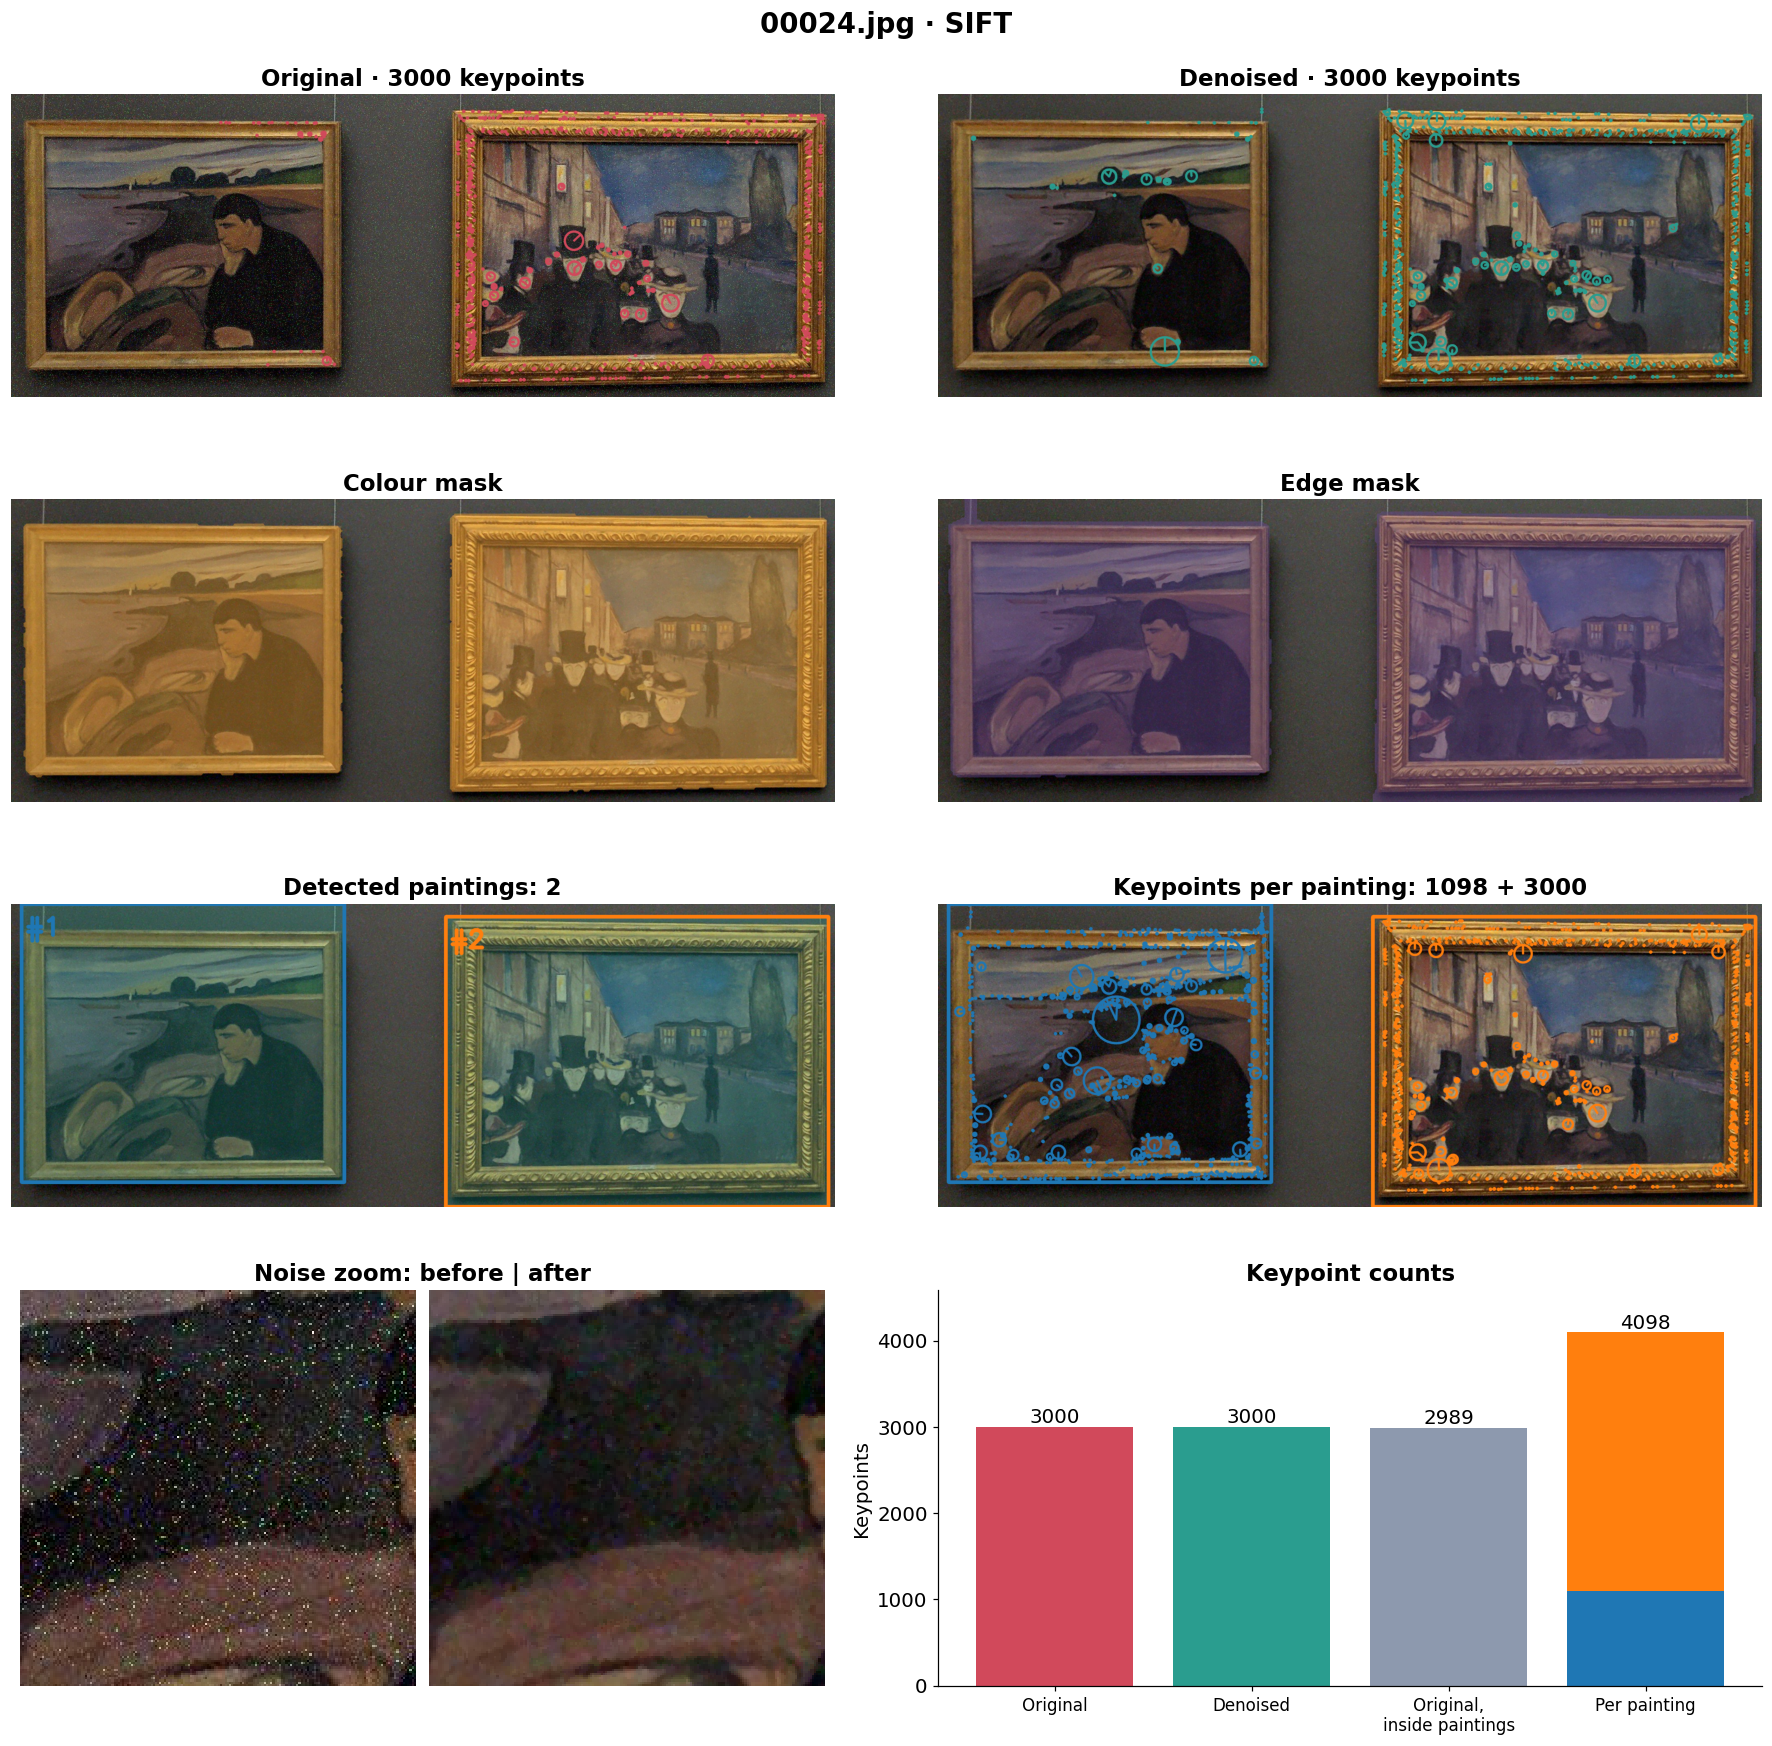

In [16]:
stats = visualize_pipeline(train_dataset.paths[24], DENOISE, method="SIFT")